In [3]:
'''
goal:
- [ ] for every detection, look at all 
detections within 20 pixels (postage stamp) plus 
the square root of the detection size, 
assign them all a detection number that is the same, 
keep the one with the largest detection size 
(in the same polarity). don’t throw it out from the dataframe

'''

'\ngoal:\n- [ ] for every detection, look at all \ndetections within 20 pixels (postage stamp) plus \nthe square root of the detection size, \nassign them all a detection number that is the same, \nkeep the one with the largest detection size \n(in the same polarity). don’t throw it out from the dataframe\n\n'

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt

import precision_recall as pr
# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import importlib

Matplotlib is building the font cache; this may take a moment.


In [2]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [3]:
df_inference = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/df_inf_dups")

In [5]:
base_path = "/lustre/lrspec/ZTF_data/efficiency_testing/"

df_eff = pd.read_csv(base_path+"df_eff_normsob")

In [6]:
np.sum(df_inference['is_smaller_dup']==0)

564547

In [7]:
np.sum(df_inference['is_smaller_dup']==1)

330228

In [221]:
def find_dups(df):
    df["dup_indices"] = np.zeros(len(df), dtype=object)
    df['is_smaller_dup'] = np.zeros(len(df)) 
    for fname in np.unique(df["filename"]):
        for quad in np.unique(df[df["filename"]==fname]["quadrant"]):
            subsection = df[(df["filename"]==fname) * (df["quadrant"]==quad)]
            for polarity in ['pos','neg']:
                for index in subsection[subsection['type']==polarity].index:
                    width = 20 + np.round(np.sqrt(subsection.loc[index]['detection_size']))
                    original_col = subsection.loc[index]["col_from_nn"] #x
                    original_row = subsection.loc[index]["row_from_nn"] #y
                    original_size = subsection.loc[index]["detection_size"]
                    dup_indices = []
                    for i, row in subsection[subsection['type']==polarity].iterrows():
                        if np.abs(original_col-row["col_from_nn"])<=width and np.abs(original_row-row["row_from_nn"])<=width:
                            if i!=index:
                                dup_indices.append(i)
                            if row["detection_size"]<original_size:
                                df.at[i, 'is_smaller_dup']=1
                            elif row["detection_size"]==original_size:
                                if np.abs(row['Diff'])>np.abs(subsection.loc[index]["Diff"]):
                                    df.at[i, 'is_smaller_dup']=1
                                elif np.abs(row['Diff'])==np.abs(subsection.loc[index]["Diff"]):
                                    if i>index: #this one is just random
                                        df.at[i, 'is_smaller_dup']=1
                    df.at[index, "dup_indices"] = np.array(dup_indices)
    return df
                    

In [ ]:
#so we are catchiing one extra here
#[813,815, 1820]
#and one extra one here 1064,1097, 1098, 1063
#and one extra here but those
#are just too close i would not believe
#even if i saw it in the wild 2348,2341, 2350, 2349, 2347


In [222]:
dupsmaybe_eff = find_dups(df_eff)

In [116]:
len(df_eff)

2942

In [104]:
np.sum(dupsmaybe_eff['is_smaller_dup'])

292.0

In [223]:
len(dupsmaybe_eff)-np.sum(dupsmaybe_eff['is_smaller_dup'])

2648.0

In [106]:
len(dupsmaybe_eff.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], keep="last"))

2653

In [107]:
dupsmaybe_eff.sort_values('detection_size', inplace=True)

In [108]:
othernodups = dupsmaybe_eff.drop_duplicates(subset=["filename", "type","row_from_implant", "col_from_implant"], keep="last")

In [109]:
othernodups[othernodups['is_smaller_dup']==True]

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,detection_size,type,row_from_nn,col_from_nn,...,height,FWHM,signal_local,sobel_ratio,sobels_x,sobels_y,sobel_norm_stdv_rat,sobel_norm_diffmax,dup_indices,is_smaller_dup
57,1656,1656,1656,1711,1004,ztf_20221017148750_000831_zi_c02_x_0017.,6,pos,1166.500000,694.666667,...,3466.509502,8.0,147.217585,25.849131,[[ 9.81029968e+01 1.95261642e+02 4.10636932e...,[[ 2.19414368e+01 -4.66267395e+00 -4.81304932e...,40.120564,25.849146,"[59, 117, 58]",1.0
425,2206,2206,2206,2273,2706,ztf_20221017148750_000831_zi_c01_x_0009.,6,pos,1015.833333,921.833333,...,607.806909,17.0,89.016147,18.094635,[[-2.54335938e+01 -3.23825073e+00 3.13086090e...,[[ 8.03112793e+00 -1.10799866e+01 -8.44438171e...,38.978638,18.094643,"[427, 426]",1.0
813,252,252,252,260,785,ztf_20221014162894_000802_zg_c03_x_0007.,12,neg,2409.833333,2734.333333,...,156.120450,32.0,80.744279,12.497815,[[ 8.65020752e-01 -2.88344421e+01 3.82046509e...,[[-2.22376404e+01 -2.05798645e+01 3.88619995e...,18.735226,12.497810,"[815, 1820]",1.0
1064,201,201,201,209,627,ztf_20221014162894_000802_zg_c01_x_0022.,56,neg,2645.160714,2788.303571,...,49.411119,23.0,61.542690,10.805243,[[ 3.72393341e+01 6.12917938e+01 -3.56809998e...,[[ 2.22273712e+01 -7.24418640e+00 -2.05232391e...,14.139237,10.805243,"[1097, 1098, 1063]",1.0
2348,2841,2841,2841,2917,4663,ztf_20221014162894_000802_zg_c01_x_0022.,149,pos,2642.187919,2788.053691,...,2368.143240,21.0,193.502800,8.800901,[[ 1.88811646e+01 7.67578125e-01 -3.54333801e...,[[ 1.26855469e+00 -9.38079834e+00 -4.30795288e...,12.103155,8.800900,"[2341, 2350, 2349, 2347]",1.0


,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,...,num_consecutive_up,num_consecutive_down,possible_up_indices,possible_down_indices,max_num_consecutive,satellite_flag_2_2_new,satellite_flag_1_7_new,satellite_flag,dup_indices,is_smaller_dup
0,0,0,0,0,0,0,0,0,0,0,...,267.0,52.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,267.0,0.0,0.0,0.0,[1],0.0
1,1,1,1,1,1,1,1,1,1,1,...,266.0,53.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,266.0,0.0,0.0,0.0,[0 2],1.0
2,2,2,2,2,2,2,2,2,2,2,...,266.0,53.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,266.0,0.0,0.0,0.0,[1 3],0.0
3,3,3,3,3,3,3,3,3,3,3,...,265.0,54.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,265.0,0.0,0.0,0.0,[2 5 6],1.0
4,4,4,4,4,4,4,4,4,4,4,...,154.0,248.0,[ 0 1 2 3 73 81 111 140 219 254 256 2...,[ 5 6 7 8 9 10 11 13 14 15 17 ...,248.0,0.0,0.0,0.0,[],0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
894770,894770,894770,894770,894770,894770,894770,894770,894770,894770,290,...,126.0,148.0,[894481 894482 894484 894485 894487 894488 894...,[894480 894483 894486 894492 894494 894498 894...,148.0,0.0,0.0,0.0,[894768 894769 894771],1.0
894771,894771,894771,894771,894771,894771,894771,894771,894771,894771,291,...,197.0,97.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894620 894627 894632 894...,197.0,0.0,0.0,0.0,[894769 894770 894772],0.0
894772,894772,894772,894772,894772,894772,894772,894772,894772,894772,292,...,201.0,52.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894627 894635 894636 894...,201.0,0.0,0.0,0.0,[894771],1.0
894773,894773,894773,894773,894773,894773,894773,894773,894773,894773,293,...,203.0,49.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894627 894639 894640 894...,203.0,0.0,0.0,0.0,[894774],0.0


In [51]:
df_inference.loc[[894768, 894769, 894770,894771,894772]].drop(columns=["Unnamed: 0",
                                                    "Unnamed: 0.1",
                                                    "Unnamed: 0.2",
                                                    "Unnamed: 0.3",
                                                    "Unnamed: 0.4",
                                                    "Unnamed: 0.5",
                                                    "Unnamed: 0.6",
                                                    "Unnamed: 0.7",
                                                    "Unnamed: 0.8",
                                                    "Unnamed: 0.9"
                                                    ])

,filename,quad,type,row_from_nn,col_from_nn,detection_size,closest_x,closest_y,Diff,snr_local,...,num_consecutive_up,num_consecutive_down,possible_up_indices,possible_down_indices,max_num_consecutive,satellite_flag_2_2_new,satellite_flag_1_7_new,satellite_flag,dup_indices,is_smaller_dup
894768,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,2979.000000,1878.000000,3.0,1889.0,2541.0,1.000000,0.050613,...,197.0,56.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894627 894632 894633 894...,197.0,0.0,0.0,0.0,[894769 894770],1.0
894769,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,2990.714286,1878.428571,7.0,1889.0,2541.0,0.571429,0.083719,...,257.0,36.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894627 894632 894633 894...,257.0,0.0,0.0,0.0,[894768 894770 894771],1.0
894770,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,2990.500000,1876.000000,2.0,1889.0,2541.0,3.000000,0.083719,...,126.0,148.0,[894481 894482 894484 894485 894487 894488 894...,[894480 894483 894486 894492 894494 894498 894...,148.0,0.0,0.0,0.0,[894768 894769 894771],1.0
894771,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,3005.208333,1877.833333,24.0,1889.0,2541.0,1.166667,0.102663,...,197.0,97.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894620 894627 894632 894...,197.0,0.0,0.0,0.0,[894769 894770 894772],0.0
894772,ztf_20221020157697_000640_zi_c13_x_0026.,1,neg,3020.800000,1878.000000,10.0,1889.0,2541.0,1.000000,0.080556,...,201.0,52.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894627 894635 894636 894...,201.0,0.0,0.0,0.0,[894771],1.0


In [107]:
df_inference.loc[894768]

Unnamed: 0.9                                                            894768
Unnamed: 0.8                                                            894768
Unnamed: 0.7                                                            894768
Unnamed: 0.6                                                            894768
Unnamed: 0.5                                                            894768
Unnamed: 0.4                                                            894768
Unnamed: 0.3                                                            894768
Unnamed: 0.2                                                            894768
Unnamed: 0.1                                                            894768
Unnamed: 0                                                                 288
filename                              ztf_20221020157697_000640_zi_c13_x_0026.
quad                                                                         1
type                                                

In [45]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [43]:
df_inference.loc[894770]

Unnamed: 0.9                                                            894770
Unnamed: 0.8                                                            894770
Unnamed: 0.7                                                            894770
Unnamed: 0.6                                                            894770
Unnamed: 0.5                                                            894770
Unnamed: 0.4                                                            894770
Unnamed: 0.3                                                            894770
Unnamed: 0.2                                                            894770
Unnamed: 0.1                                                            894770
Unnamed: 0                                                                 290
filename                              ztf_20221020157697_000640_zi_c13_x_0026.
quad                                                                         1
type                                                

In [55]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [185]:
pred = np.load("/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020157697_000640_zi_c13_x_0026._extraction_predsarray_1_predsarray.npy")

In [186]:
file = "/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020157697_000640_zi_c13_x_0026.fits.fz"
hdul = fits.open(file)
file1_array = hdul[1].data

In [191]:
files = "/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020157697_000640_zi_c13_x.fits.fz"
hduls = fits.open(files)
file1_arrays = hduls[1].data

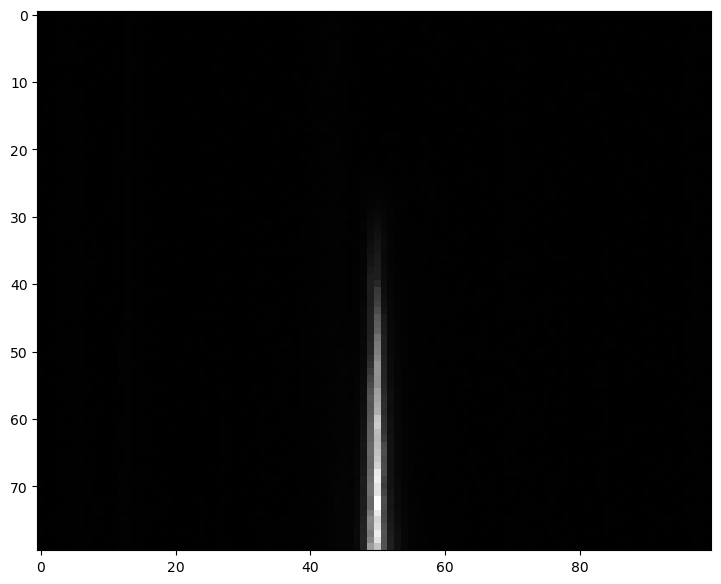

In [200]:
plt.imshow(file1_arrays[2541-40:2541+40,1889-50:1889+50])


In [76]:
wid=10
nrow, ncol = 3080, 3072

In [201]:
file = df_inference[df_inference['filename']=='ztf_20221020157697_000640_zi_c13_x_0026.'].drop(columns=["Unnamed: 0",
                                                    "Unnamed: 0.1",
                                                    "Unnamed: 0.2",
                                                    "Unnamed: 0.3",
                                                    "Unnamed: 0.4",
                                                    "Unnamed: 0.5",
                                                    "Unnamed: 0.6",
                                                    "Unnamed: 0.7",
                                                    "Unnamed: 0.8",
                                                    "Unnamed: 0.9"
                                                    ])

In [202]:
inquad = file[file['quad']==1]

In [203]:
inquad[inquad['type']=='neg']['col_from_nn']

894637    1877.812500
894638    1878.000000
894639    1878.285714
894640    1878.062500
894641    1878.000000
             ...     
894770    1876.000000
894771    1877.833333
894772    1878.000000
894773    1878.000000
894774    1876.000000
Name: col_from_nn, Length: 138, dtype: float64

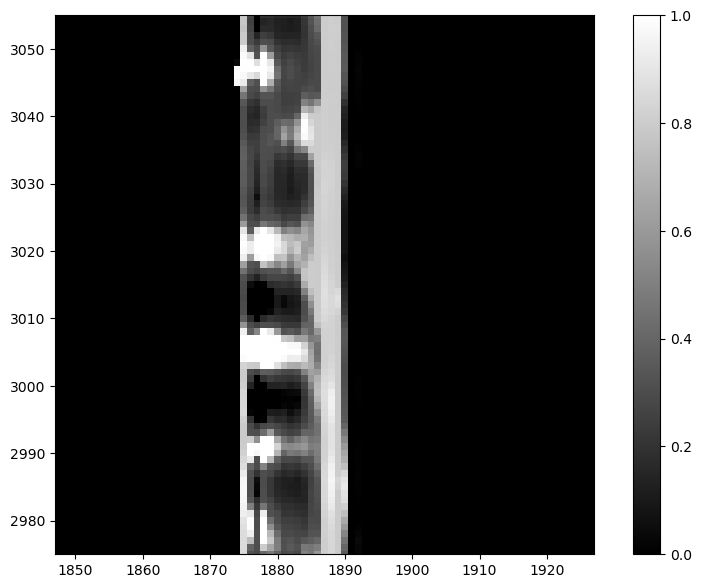

In [204]:
plt.imshow(pred[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid).T)
plt.ylim(3005+wid-40, 3005+wid+40)
plt.xlim(1877+wid-40, 1877+wid+40)
# plt.xlim(2850,2880)
plt.colorbar()

In [206]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020157697_000640_zi_c13_x_0026._extraction_predsarray_1_predsarray.npy


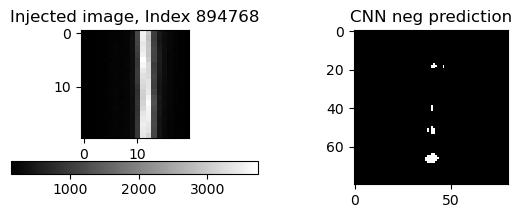

/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020157697_000640_zi_c13_x_0026._extraction_predsarray_1_predsarray.npy


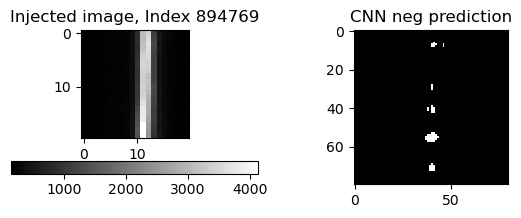

/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020157697_000640_zi_c13_x_0026._extraction_predsarray_1_predsarray.npy


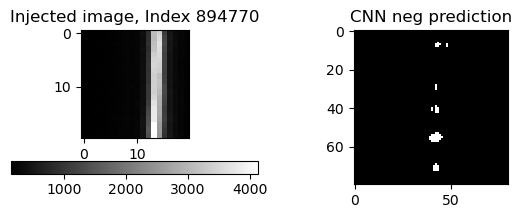

/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020157697_000640_zi_c13_x_0026._extraction_predsarray_1_predsarray.npy


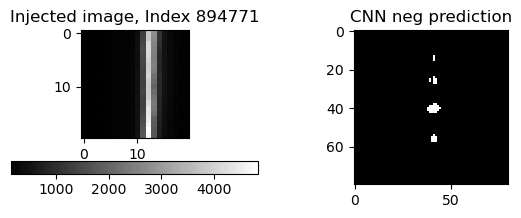

/lustre/lrspec/ZTF_data/science_extractions/1020/ztf_20221020157697_000640_zi_c13_x_0026._extraction_predsarray_1_predsarray.npy


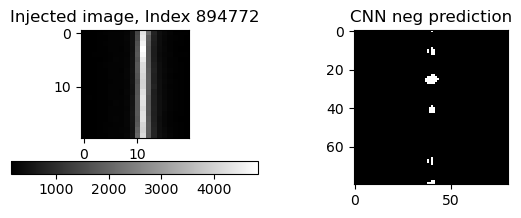

In [207]:
for index in [894768, 894769, 894770,894771,894772]:#0,1,2,3,5,6,7,8,10,11,13,14,15]:#[425,426,427]:#series.index:#[2, 865, 874, 2057]:
    rff.inspect_stamp_and_map(df_inference, index, eff=False,size=40)

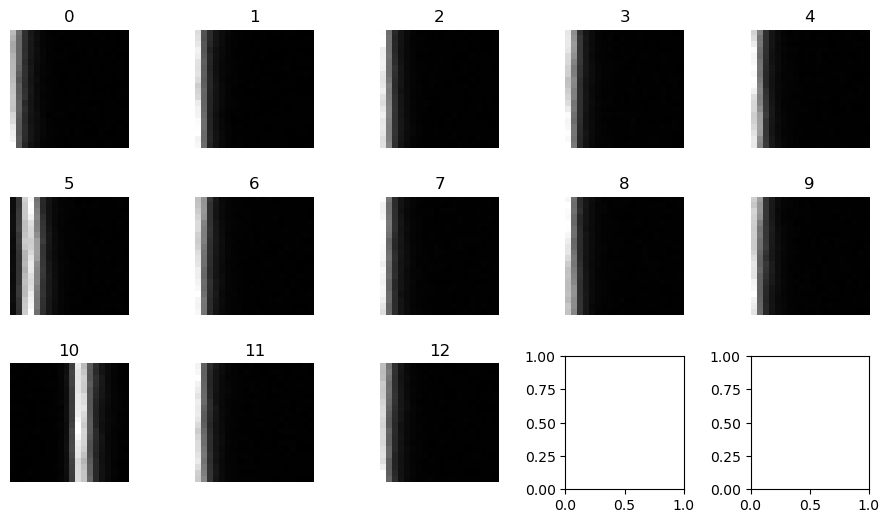

In [20]:
rff.inspect_df_w_stamp_color(df_inference.loc[[0,1,2,3,5,6,7,8,10,11,13,14,15]])

In [ ]:
ztf_20221020157697_000640_zi_c13_x_0026

In [151]:
path = '/lustre/lrspec/ZTF_data/science_extractions/1020/'
pred = 'ztf_20221020297847_000449_zr_c15_x_0006.'
extra = '_extraction_predsarray_1_predsarray.npy'

In [152]:
it = np.load(path+pred+extra)

In [153]:
np.shape(it)

(9339120, 5)

In [154]:
wid = 10
abst_thr = .9999


folder_path = "/lustre/lrspec/ZTF_data/science_extractions/1020"
newpath = folder_path+"/redo_nov/"
# dframe=pd.read_csv(newpath+file+"_matched_corrected")

# # # List all the files in the folder
files = [f for f in os.listdir(folder_path) if f.endswith('alllist')]  # Adjust this to your file format
for file in files:
    print(file)
#     df = pd.read_csv(os.path.join(folder_path, file))
    
# # #pos
#     df_nocr = df[df["type"] != "cr"]
#     df_noboth = df_nocr[df_nocr["type"] != "both"]
#     df_reduced_edges= rff.reduce_edges(df_noboth, 15)
    
#     quad = file[-8]
#     newpath = folder_path+"/redo_nov/"
    
#     xy_path = "/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/"
#     xy_file = xy_path+file[:-20]+quad+".fits"
    
#     data_list = []
    
    
#     # closest_amounts_c = []
#     with fits.open(xy_file) as hdul_xy:
#         for i, rrow in df_reduced_edges.iterrows():
#             col = rrow["col_from_nn"]
#             target_x = col+10
#         # print(xy_file)
#             data = hdul_xy[1].data  
#             stored_x = data["X"][:25]  # Column "X"
#             stored_y = data["Y"][:25]
#             closest_idx = np.argmin(np.abs(stored_x - target_x))
#             closest_x, closest_y = stored_x[closest_idx], stored_y[closest_idx]
#             if np.abs(closest_x-target_x)<=10:
#                 # plt.imshow(np.sqrt(file1_array[(int(closest_y))-20:(int(closest_y))+20, (int(closest_x))-20:(int(closest_x))+20]))
#                 # plt.scatter(20,20)
#                 # plt.show()    
#                     # Retrieve the closest (x, y) match
#                 data_list.append({"filename": rrow["filename"], "quad":quad, "type":rrow["type"],"row_from_nn":rrow["row_from_nn"],  
#                                   "col_from_nn":rrow["col_from_nn"], "detection_size":rrow["detection_size"],
#                                  "closest_x": closest_x, "closest_y":closest_y, "Diff":np.abs(closest_x-target_x)})
#                 dframe = pd.DataFrame(data_list)
#                 dframe.to_csv(newpath+file+"_matched_corrected")

ztf_20221020154120_000640_zi_c14_x_0001.fits.fz2alllist
ztf_20221020138241_000686_zi_c16_x_0005.fits.fz4alllist
ztf_20221020157697_000640_zi_c08_x_0015.fits.fz1alllist
ztf_20221020138241_000686_zi_c08_x_0022.fits.fz1alllist
ztf_20221020141806_000686_zi_c06_x_0016.fits.fz2alllist
ztf_20221020148032_000686_zg_c11_x_0005.fits.fz4alllist
ztf_20221020294271_000449_zr_c02_x_0011.fits.fz2alllist
ztf_20221020297847_000449_zr_c07_x_0017.fits.fz1alllist
ztf_20221020294271_000449_zr_c09_x_0019.fits.fz1alllist
ztf_20221020163819_000640_zg_c10_x_0008.fits.fz1alllist
ztf_20221020297847_000449_zr_c08_x_0026.fits.fz2alllist
ztf_20221020294271_000449_zr_c06_x_0028.fits.fz2alllist
ztf_20221020163819_000640_zg_c06_x_0002.fits.fz4alllist
ztf_20221020138241_000686_zi_c13_x_0008.fits.fz3alllist
ztf_20221020157697_000640_zi_c04_x_0001.fits.fz1alllist
ztf_20221020148032_000686_zg_c14_x_0008.fits.fz3alllist
ztf_20221020297847_000449_zr_c10_x_0029.fits.fz3alllist
ztf_20221020154120_000640_zi_c14_x_0009.fits.fz1

In [157]:
dfone = pd.read_csv(folder_path+"/ztf_20221020297847_000449_zr_c15_x_0006.fits.fz1alllist")

In [161]:
dftwo = pd.read_csv(newpath+"/ztf_20221020297847_000449_zr_c15_x_0006.fits.fz1alllist"+"_matched_corrected")

In [164]:
dfthree = pd.read_csv(newpath+"df_all_corrected")

In [171]:
df_sobel = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/df_sobel")

/tmp/ipykernel_1033/1361591459.py:1: DtypeWarning: Columns (16) have mixed types. Specify dtype option on import or set low_memory=False.
  df_sobel = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/df_sobel")


In [174]:
df_snr_3=pd.read_csv(
    "/lustre/lrspec/ZTF_data/efficiency_testing/df_snr_3")

In [177]:
dfsnr = pd.read_csv(
    "/lustre/lrspec/ZTF_data/efficiency_testing/df_snr_sobel")

In [178]:
df = dfsnr
mine = df[df['filename']=='ztf_20221020297847_000449_zr_c15_x_0006.']
mine = mine[mine['quad']==1]

In [180]:
df = df_inference
mine = df[df['filename']=='ztf_20221020297847_000449_zr_c15_x_0006.']
mine = mine[mine['quad']==1]

In [181]:
np.min(mine[mine['type']=='neg']['col_from_nn'])
#looking for col at 1887ish

2835.0

In [148]:
dfinit[dfinit['type']=='pos']

,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size
0,0,ztf_20221020297847_000449_zr_c15_x_0006.,pos,1.0,2871.0,3.0
1,1,ztf_20221020297847_000449_zr_c15_x_0006.,pos,9.0,2871.0,3.0
2,2,ztf_20221020297847_000449_zr_c15_x_0006.,pos,22.0,2871.0,9.0
3,3,ztf_20221020297847_000449_zr_c15_x_0006.,pos,39.5,2872.0,6.0
4,4,ztf_20221020297847_000449_zr_c15_x_0006.,pos,65.0,2857.0,3.0
...,...,...,...,...,...,...
193,193,ztf_20221020297847_000449_zr_c15_x_0006.,pos,3013.0,2872.0,1.0
194,194,ztf_20221020297847_000449_zr_c15_x_0006.,pos,3036.5,2871.5,6.0
195,195,ztf_20221020297847_000449_zr_c15_x_0006.,pos,3049.5,2871.0,8.0
196,196,ztf_20221020297847_000449_zr_c15_x_0006.,pos,3053.0,2837.0,3.0


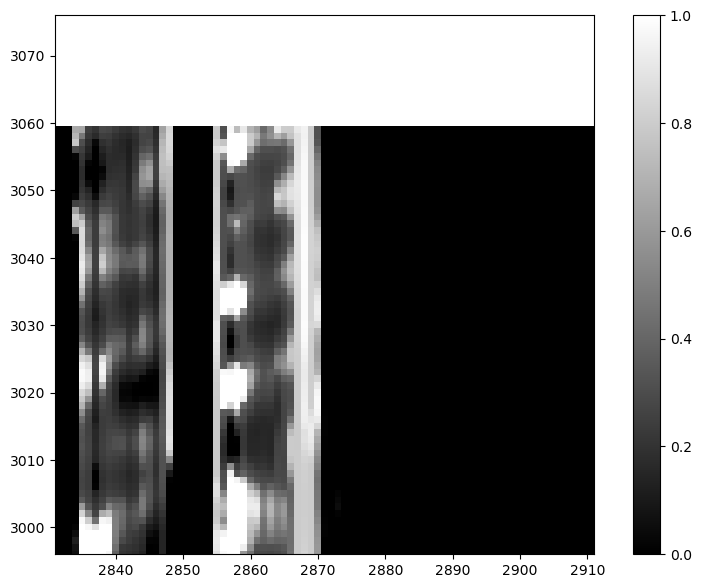

In [147]:
plt.imshow(pred[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid).T)
plt.ylim(3036-40, 3036+40)#3005-40, 3005+40)
plt.xlim(2871-40,2871+40)#1877-40, 1877+40)
# plt.xlim(2850,2880)
plt.colorbar()

In [75]:
big = dupsmaybe_eff[dupsmaybe_eff['is_smaller_dup']==0].drop(columns=["Unnamed: 0",
                                                    "Unnamed: 0.1",
                                                    "Unnamed: 0.2",
                                                    "Unnamed: 0.3",
                                                    "Unnamed: 0.4"
                                                    ])

In [76]:
series = big[big.duplicated(subset=["filename", "type","row_from_implant", "col_from_implant"], keep=False)==True]

In [77]:
series

,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,closest_x,...,height,FWHM,signal_local,sobel_ratio,sobels_x,sobels_y,sobel_norm_stdv_rat,sobel_norm_diffmax,dup_indices,is_smaller_dup


In [70]:
series['Diff']

57      -3.666667
58       3.000000
425     -3.833333
426      1.000000
559      1.000000
595    -11.000000
824     -1.000000
825     -4.000000
1085    -4.000000
1086     0.000000
Name: Diff, dtype: float64

In [211]:
dupsmaybe_eff.loc[[813,815, 1820]].drop(columns=["Unnamed: 0",
                                                    "Unnamed: 0.1",
                                                    "Unnamed: 0.2",
                                                    "Unnamed: 0.3",
                                                    "Unnamed: 0.4"
                                                    ])

NameError: name 'dupsmaybe_eff' is not defined

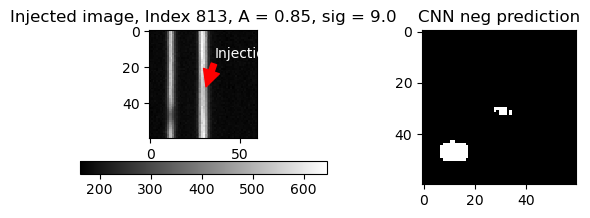

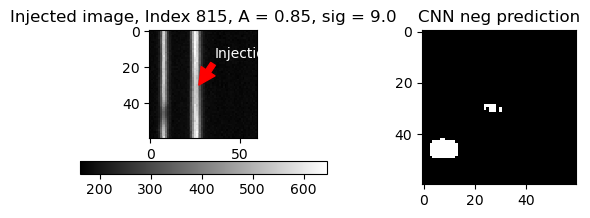

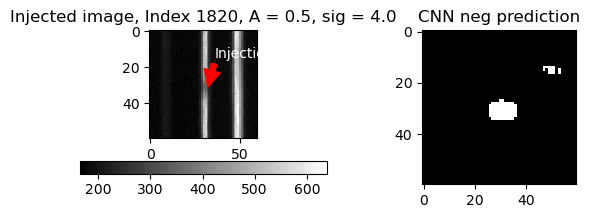

In [95]:
for index in [813,815, 1820]:#[425,426,427]:#series.index:#[2, 865, 874, 2057]:
    rff.inspect_stamp_and_map(dupsmaybe_eff, index, size=30)

,filename,detection_size,type,row_from_nn,col_from_nn,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,closest_x,...,height,FWHM,signal_local,sobel_ratio,sobels_x,sobels_y,sobel_norm_stdv_rat,sobel_norm_diffmax,dup_indices,is_smaller_dup
2,ztf_20221014162894_000802_zg_c01_x_0008.,42,pos,555.380952,2787.976190,2799.0,570.0,1.3,8.0,2798.0,...,222.845728,17.0,52.980416,10.900368,[[ 1.85939636e+01 5.42543793e+01 1.09754791e...,[[ 2.98595886e+01 2.29092865e+01 4.06089783e...,25.556520,10.900372,[],0.0
865,ztf_20221014162894_000802_zg_c01_x_0008.,85,pos,399.741176,2797.494118,2806.0,410.0,10.0,3.0,2806.0,...,3768.258103,9.0,148.628681,3.869837,[[-1.54024841e+02 -1.09688086e+03 -1.33850757e...,[[-1.82736206e+01 2.05258179e+00 -2.32540894e...,3.278037,3.869837,[874],0.0
874,ztf_20221014162894_000802_zg_c01_x_0008.,15,pos,390.600000,2787.800000,2806.0,410.0,10.0,3.0,2798.0,...,3385.803356,9.0,148.607830,2.945551,[[ 4.10503082e+01 7.48347321e+01 -2.09775391e...,[[ 2.41026764e+01 -2.54322052e+01 -4.13392944e...,3.502551,2.945551,[865],1.0
2057,ztf_20221014162894_000802_zg_c01_x_0008.,114,pos,414.385965,1599.052632,1608.0,425.0,3.0,4.0,1608.0,...,1027.434089,11.0,92.821125,4.488717,[[-5.22933960e+00 2.23300171e+00 1.04076996e...,[[ 3.49301147e+00 2.11477356e+01 8.00871277e...,5.630954,4.488716,[],0.0


In [46]:
def add_num_in_file_in_star(df):
    df['num_in_file_in_star']=np.zeros(len(df))
    for filename, group in df.groupby('filename'):     
        for quadnum, quadgroup in group.groupby('quadrant'):
            for starx, stargroup in quadgroup.groupby('closest_x'):
                num_in_file_in_star = len(stargroup)
                for index in stargroup.index:
                    df.at[index, 'num_in_file_in_star']=num_in_file_in_star
    return df

(array([ 5.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., 15.]),
 array([ 5.,  6.,  7.,  8.,  9., 10., 11., 12., 13., 14., 15.]),
 <BarContainer object of 10 artists>)

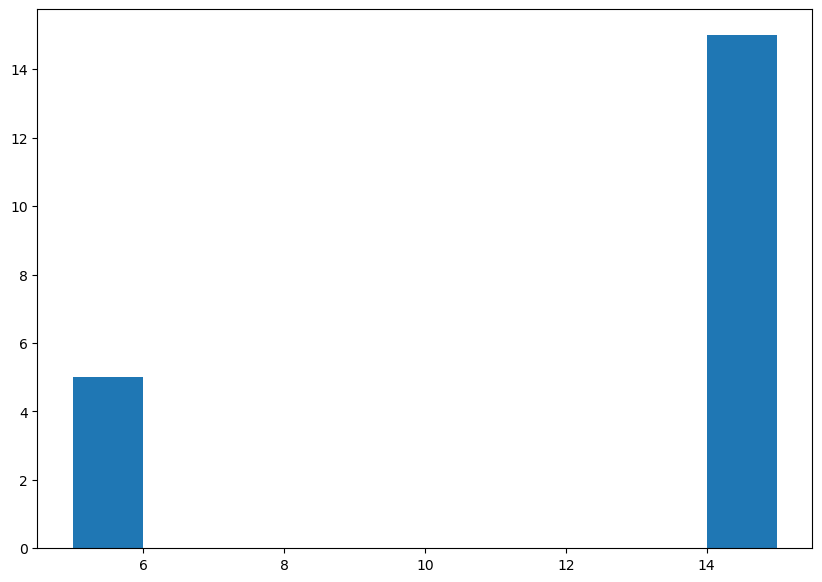

In [219]:
plt.hist(numinstar['num_in_file_in_star'])

In [224]:
df_eff_again = add_num_in_file_in_star(dupsmaybe_eff)

In [226]:
df_eff_again.to_csv(base_path+"df_eff_wdups")

In [228]:
df_inference_again = add_num_in_file_in_star(df_inference)

In [230]:
df_inference_again.drop(columns=['sobels_x','sobels_y'], inplace=True)

In [231]:
df_inference_again

,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,...,num_consecutive_down,possible_up_indices,possible_down_indices,max_num_consecutive,satellite_flag_2_2_new,satellite_flag_1_7_new,satellite_flag,dup_indices,is_smaller_dup,num_in_file_in_star
0,0,0,0,0,0,0,0,0,0,0,...,52.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,267.0,0.0,0.0,0.0,[1],0.0,194.0
1,1,1,1,1,1,1,1,1,1,1,...,53.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,266.0,0.0,0.0,0.0,[0 2],1.0,194.0
2,2,2,2,2,2,2,2,2,2,2,...,53.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,266.0,0.0,0.0,0.0,[1 3],0.0,194.0
3,3,3,3,3,3,3,3,3,3,3,...,54.0,[ 4 9 12 16 18 22 26 30 34 44 47 ...,[ 6 13 33 36 42 45 59 75 83 87 89 ...,265.0,0.0,0.0,0.0,[2 5 6],1.0,194.0
4,4,4,4,4,4,4,4,4,4,4,...,248.0,[ 0 1 2 3 73 81 111 140 219 254 256 2...,[ 5 6 7 8 9 10 11 13 14 15 17 ...,248.0,0.0,0.0,0.0,[],0.0,268.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
894770,894770,894770,894770,894770,894770,894770,894770,894770,894770,290,...,148.0,[894481 894482 894484 894485 894487 894488 894...,[894480 894483 894486 894492 894494 894498 894...,148.0,0.0,0.0,0.0,[894768 894769 894771],1.0,174.0
894771,894771,894771,894771,894771,894771,894771,894771,894771,894771,291,...,97.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894620 894627 894632 894...,197.0,0.0,0.0,0.0,[894769 894770 894772],0.0,174.0
894772,894772,894772,894772,894772,894772,894772,894772,894772,894772,292,...,52.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894627 894635 894636 894...,201.0,0.0,0.0,0.0,[894771],1.0,174.0
894773,894773,894773,894773,894773,894773,894773,894773,894773,894773,293,...,49.0,[894480 894481 894482 894483 894484 894485 894...,[894528 894603 894604 894627 894639 894640 894...,203.0,0.0,0.0,0.0,[894774],0.0,174.0


In [232]:
df_inference_again.to_csv(base_path+"df_inf_wdups")

Text(0.5, 1.0, 'Number of transients in same streak (in same file)')

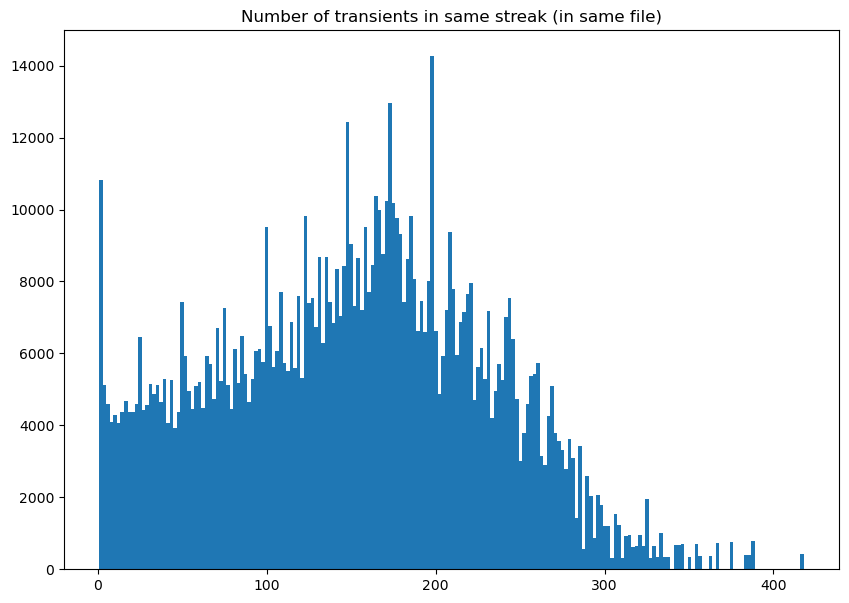

In [238]:
plt.hist(df_inference_again['num_in_file_in_star'], bins=200)
plt.title("Number of transients in same streak (in same file)")

In [41]:
indices = []
for i, row in df_inference[df_inference['is_smaller_dup']==0].iterrows():
    if ('ztf_20221020148032_000686_zg' in row['filename']) & (row['quad']==1):
        indices.append(i)
        

In [43]:
len(indices)

27705

In [ ]:
maybe = df_inference.drop(columns=["Unnamed: 0",
                                                    "Unnamed: 0.1",
                                                    "Unnamed: 0.2",
                                                    "Unnamed: 0.3",
                                                    "Unnamed: 0.4",
                                                    "Unnamed: 0.5",
                                                    "Unnamed: 0.6",
                                                    "Unnamed: 0.7",
                                                    "Unnamed: 0.8",
                                                    "Unnamed: 0.9"
                                                    ]).loc[indices]

In [ ]:
maybe = add_num_in_file_in_star(maybe)

In [54]:
list_of_filenames = []
for i, row in maybe[maybe['num_in_file_in_star']>50].iterrows():
    lc_filename = 'lightcurve_'+row['filename'][:-1]+'_'+str(row['quadrant'])+'_'+str(int(row['closest_x']))+'_'+str(int(row['closest_y']))+'.csv'
    if lc_filename not in list_of_filenames:
        list_of_filenames.append(lc_filename)

In [57]:
list_of_filenames

['lightcurve_ztf_20221020148032_000686_zg_c03_x_0004_1_965_825.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c03_x_0004_1_1915_2161.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c10_x_0020_1_2738_2741.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c01_x_0014_1_140_236.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c01_x_0014_1_2765_404.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c09_x_0024_1_2413_2555.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c14_x_0000_1_1462_2431.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c14_x_0000_1_3022_2768.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c14_x_0000_1_1069_1803.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c14_x_0000_1_1694_205.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c07_x_0024_1_2171_2308.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c07_x_0024_1_2923_1737.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c03_x_0019_1_965_825.csv',
 'lightcurve_ztf_20221020148032_000686_zg_c03_x_0019_1_1915_2161.csv',
 'lightcurve_z